# Задача 1. Геометрия детектора

Сфера $R = 2$ м, $N = 40$ ФЭУ с плоскими фотокатодами $r = 10$ см, $a = 0.5$.

**Расстановка ФЭУ.** Используем спираль Фибоначчи: $\cos	heta_i = 1 - 2(i+0.5)/N$ (равные по площади пояса),
$\phi_i = i\cdot\pi(3-\sqrt5)$ («золотой угол»). Координаты хранятся в `numpy`-массиве формы `(N, 3)` —
строка = ФЭУ; это позволяет векторно считать скалярные произведения со всеми ФЭУ сразу.

**Принадлежность точки ФЭУ.** Катод — диск радиуса $r$, касающийся сферы в $ec c_k = Rec n_k$.
Точка $ec p$ на сфере «попадает» в проекцию диска, если $|ec p_T|^2 = p^2 - (ec p\cdotec n_k)^2 \le r^2$ и $ec p\cdotec n_k>0$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from detector import Detector

det = Detector(R=2.0, N=40, r=0.10, a=0.5)
print(det.pmt_positions.shape)
det.pmt_positions[:5]

(40, 3)


array([[ 0.16104292,  0.41420427,  1.95      ],
       [-0.68149594, -0.33624883,  1.85      ],
       [ 0.92965601, -0.27062835,  1.75      ],
       [-0.58680971,  0.96599915,  1.65      ],
       [-0.24582308, -1.23978668,  1.55      ]])

## Проверка равномерности

Мин. расстояние между ФЭУ: 0.977 м (2r = 0.2 м)
Центр масс ФЭУ: [0.0024 0.0029 0.    ]
Доля покрытия поверхности: 2.5016%


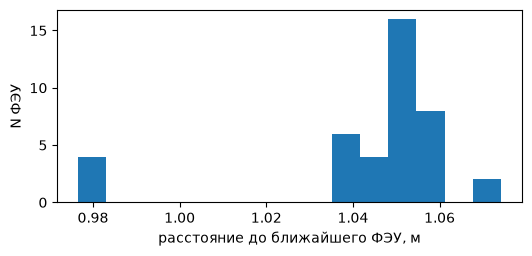

In [2]:
print(f"Мин. расстояние между ФЭУ: {det.min_pmt_distance():.3f} м (2r = {2*det.r} м)")
print(f"Центр масс ФЭУ: {det.pmt_positions.mean(axis=0).round(4)}")
print(f"Доля покрытия поверхности: {det.coverage():.4%}")

d = np.linalg.norm(det.pmt_positions[:, None] - det.pmt_positions[None], axis=2)
np.fill_diagonal(d, np.inf)
plt.figure(figsize=(6, 2.5))
plt.hist(d.min(axis=1), bins=15)
plt.xlabel('расстояние до ближайшего ФЭУ, м'); plt.ylabel('N ФЭУ')
plt.show()

## Проверка метода `pmt_index` (Монте-Карло)
Случайные изотропные точки на сфере: доля попавших должна совпасть с аналитическим покрытием.

In [3]:
rng = np.random.default_rng(1)
Mpts = 2_000_000
phi = rng.uniform(0, 2*np.pi, Mpts); ct = rng.uniform(-1, 1, Mpts); st = np.sqrt(1-ct**2)
points = det.R * np.stack([st*np.cos(phi), st*np.sin(phi), ct], axis=1)
idx = det.pmt_index(points)
frac = (idx >= 0).mean()
print(f"MC: {frac:.5f} ± {np.sqrt(frac/Mpts):.5f},  аналитика: {det.coverage():.5f}")
print("центр каждого ФЭУ принадлежит ему:", np.array_equal(det.pmt_index(det.pmt_positions), np.arange(det.N)))

MC: 0.02505 ± 0.00011,  аналитика: 0.02502
центр каждого ФЭУ принадлежит ему: True


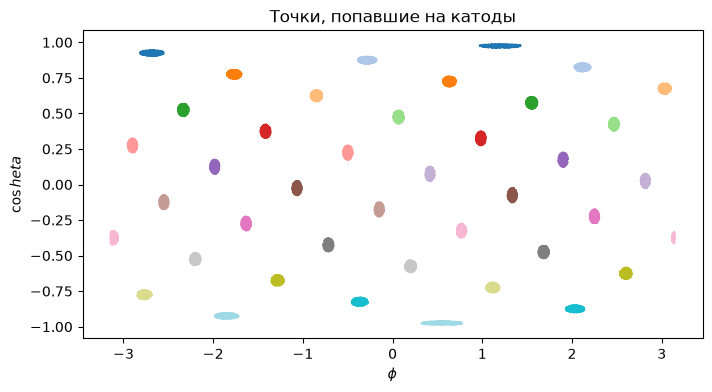

In [4]:
hit = idx >= 0
th, ph = np.arccos(points[:, 2]/det.R), np.arctan2(points[:, 1], points[:, 0])
plt.figure(figsize=(8, 4))
plt.scatter(ph[hit][:20000], np.cos(th[hit][:20000]), c=idx[hit][:20000], s=0.5, cmap='tab20')
plt.xlabel(r'$\phi$'); plt.ylabel(r'$\cos	heta$'); plt.title('Точки, попавшие на катоды')
plt.show()

## Визуализация k3d

In [5]:
import k3d
plot = k3d.plot()
plot += k3d.points(det.pmt_positions.astype(np.float32), point_size=2*det.r, color=0xff8800)
plot += k3d.points((points[~hit][:5000]).astype(np.float32), point_size=0.01, color=0x8888ff, opacity=0.3)
plot.display()

Output()